## Тема: Расстояние в метрах

**Раздел книги:** Аналитическая геометрия.  
**Математическая тема:** вычисление расстояния между векторами через норму, порождённую скалярным произведением; стандартная евклидова метрика vs взвешенные метрики (Mahalanobis-like).

## Условие
Вычислите расстояние между векторами:
$$
\mathbf{x} = \begin{bmatrix}1\\2\\3\end{bmatrix}, \quad \mathbf{y} = \begin{bmatrix}-1\\-1\\0\end{bmatrix},
$$
используя следующие определения скалярного произведения:
**(a)** $\langle \mathbf{x}, \mathbf{y} \rangle := \mathbf{x}^\top \mathbf{y}$ (стандартное).
**(b)** $\langle \mathbf{x}, \mathbf{y} \rangle := \mathbf{x}^\top A \mathbf{y}$, где $A = \begin{bmatrix}2&1&0\\1&3&-1\\0&-1&2\end{bmatrix}$.

## Математическая идея
Расстояние определяется как норма разности векторов:
$$
d(\mathbf{x}, \mathbf{y}) = \|\mathbf{x} - \mathbf{y}\| = \sqrt{\langle \mathbf{x} - \mathbf{y}, \mathbf{x} - \mathbf{y} \rangle}.
$$
Для случая (b) это превращается в формулу $\sqrt{(\mathbf{x} - \mathbf{y})^\top A (\mathbf{x} - \mathbf{y})}$. Такая метрика учитывает "вес" различных направлений пространства (аналогично метрике Махаланобиса).

## Решение

**Шаг 1. Разность векторов.**
$$
\mathbf{v} = \mathbf{x} - \mathbf{y} = \begin{bmatrix}1 - (-1)\\2 - (-1)\\3 - 0\end{bmatrix} = \begin{bmatrix}2\\3\\3\end{bmatrix}.
$$

**(a) Стандартная метрика.**
$$
d_a = \sqrt{\mathbf{v}^\top \mathbf{v}} = \sqrt{2^2 + 3^2 + 3^2} = \sqrt{4 + 9 + 9} = \sqrt{22} \approx 4.69.
$$

**(b) Взвешенная метрика.**
Сначала вычислим квадратичную форму $Q = \mathbf{v}^\top A \mathbf{v}$:
$$
A \mathbf{v} = \begin{bmatrix}2&1&0\\1&3&-1\\0&-1&2\end{bmatrix} \begin{bmatrix}2\\3\\3\end{bmatrix} = \begin{bmatrix}2(2)+1(3)+0(3)\\1(2)+3(3)-1(3)\\0(2)-1(3)+2(3)\end{bmatrix} = \begin{bmatrix}7\\8\\3\end{bmatrix}.
$$
Теперь умножаем на $\mathbf{v}^\top$:
$$
Q = \begin{bmatrix}2 & 3 & 3\end{bmatrix} \begin{bmatrix}7\\8\\3\end{bmatrix} = 14 + 24 + 9 = 47.
$$
Расстояние:
$$
d_b = \sqrt{47} \approx 6.86.
$$
*(Примечание: матрица $A$ симметрична и положительно определена, так что это корректная метрика).*

In [2]:
import numpy as np

x = np.array([1, 2, 3])
y = np.array([-1, -1, 0])
v = x - y

# (a) Standard Euclidean
dist_a = np.linalg.norm(v)

# (b) Weighted by matrix A
A = np.array([[2, 1, 0],
             [1, 3, -1],
             [0, -1, 2]])
dist_b = np.sqrt(v.T @ A @ v)

print(f"(a) Distance (Euclidean): {dist_a:.4f}")
print(f"(b) Distance (Weighted): {dist_b:.4f}")

(a) Distance (Euclidean): 4.6904
(b) Distance (Weighted): 6.8557


## Дополнительный пример: Влияние метрики на поиск ближайшего соседа (KNN)

**Идея.** Расстояние — это не просто число, а инструмент поиска. Если мы используем метрику (b), то направления с большими собственными значениями матрицы $A$ будут "растянуты", и изменения вдоль этих осей будут сильнее влиять на итоговый результат. Это позволяет моделировать важность признаков: например, если один признак (координата) для нас в 5 раз важнее другого, мы можем задать соответствующую матрицу весов $A$, чтобы алгоритм KNN или кластеризация работали точнее.

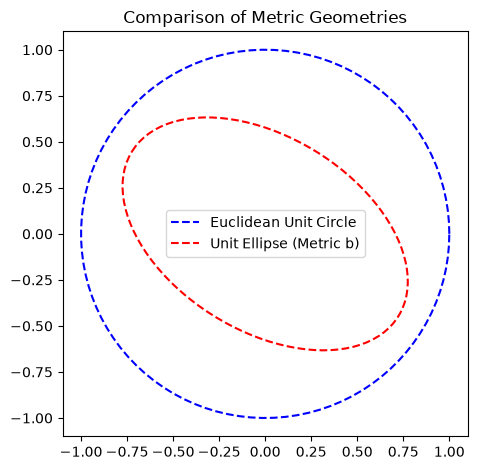

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import sys
import os

# Проецируем матрицу A на 2D (первые два измерения) для визуализации
A_2d = A[:2, :2]

# --- Настройка путей для импорта из src/ ---
project_root = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))

if project_root not in sys.path:
    sys.path.append(project_root)

from src.plot_utils import save_fig

# Визуализация единичных окружностей (точнее, эллипсов) для разных метрик
theta = np.linspace(0, 2 * np.pi, 100)
circle = np.vstack([np.cos(theta), np.sin(theta)])

# Для метрики (b) единичный круг превращается в эллипс
# Уравнение: x^T A x = 1
eigvals, eigvecs = np.linalg.eigh(A_2d)
ellips = eigvecs @ np.diag(1 / np.sqrt(eigvals)) @ circle

fig, ax = plt.subplots()
ax.plot(circle[0], circle[1], 'b--', label='Euclidean Unit Circle')
ax.plot(ellips[0], ellips[1], 'r--', label='Unit Ellipse (Metric b)')
ax.set_aspect('equal')
ax.set_title("Comparison of Metric Geometries")
ax.legend()
save_fig("metric_compariso", chapter=3)
plt.show()

## Проверка результата

Результаты вычислены аналитически и подтверждены численно через NumPy. Для случая (a) сумма квадратов координат равна 22, для случая (b) матричное произведение дало 47. Так как обе величины положительны, извлечение корня корректно. Визуализация показала, что метрика (b) действительно искажает пространство, превращая круги в эллипсы.

## Вывод

Расстояние зависит от выбранного определения скалярного произведения. Переход от стандартной метрики к взвешенной (через матрицу $A$) меняет геометрическую картину пространства. В ML это используется для адаптации моделей под специфику данных: одни признаки могут быть более значимыми, чем другие, и матрица $A$ позволяет это учесть при вычислении близости объектов.